# Local RLCTs of bivariate polynomials

The functions are defined in `rlct.py`, which must be in the same folder as this notebook. Run `help(rlct)` or `rlct?` to see the documentation of a function.

In [11]:
from rlct import *
import time
import tracemalloc

In [12]:
x, y = polygens(QQ, 'x,y')

In [13]:
f = y^4+y^3+(1+4*x)*y^2+(2*x+3*x^2)*y+x^2
rlct(f,verbose=True)

x^2 + 2*x*y + y^2
Polynomial Iterate: x^4 - 4*x^3*y + 6*x^2*y^2 - 4*x*y^3 + y^4 - 2*x^2*y + x*y^2 + y^3 + y^2
x^4 - 2*x^2*y + y^2
Polynomial Iterate: x^8 - 4*x^7 + 4*x^6*y + 7*x^6 - 12*x^5*y + 6*x^4*y^2 - 3*x^5 + 15*x^4*y - 12*x^3*y^2 + 4*x^2*y^3 - 2*x^3*y + 9*x^2*y^2 - 4*x*y^3 + y^4 + x*y^2 + y^3 + y^2
-3*x^5 + y^2
number of change of variables: 1


7/10

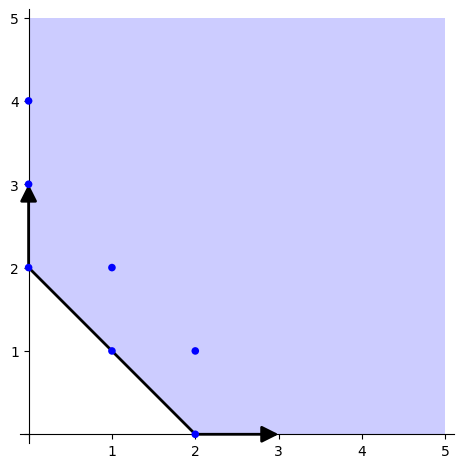

In [6]:
print_poly(f)

In [5]:
#TIME

M = matrix([[x+y,x^2],[x^2,y^2]])

n = 3

W = []

r = 2

for i in range(n):

    print("Depth: " + str(i+1))

    
    W.append(M)

    t0 = time.time()
    g = PNN_polynomial(W,r)
    t1 = time.time()
    print(f"PNN Time: {t1 - t0:.4f}s")

    l = rlct(g)
    t2 = time.time()
    print(f"RLCT Time: {t2 - t1:.4f}s")

    print("RLCT: " + str(l))

    print(f"Total time: {t2 - t0:.4f} s")

Depth: 1
PNN Time: 0.0131s
RLCT Time: 0.0147s
RLCT: 3/4
Total time: 0.0279 s
Depth: 2
PNN Time: 0.0005s
RLCT Time: 0.0168s
RLCT: 1/4
Total time: 0.0174 s
Depth: 3
PNN Time: 0.0008s
RLCT Time: 0.0691s
RLCT: 3/28
Total time: 0.0699 s


In [6]:
#MEMORY

M = matrix([[x+y,x^2],[x^2,y^2]])

n = 5

W = []

r = 2

for i in range(n):

    print("Depth: " + str(i+1))

    
    W.append(M)

    tracemalloc.start()
    g = PNN_polynomial(W,r)
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    print(f"PNN Peak Allocated: {peak / int(1024):.1f} KB")

    tracemalloc.start()
    l = rlct(g)
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    print(f"RLCT Peak Allocated: {peak / int(1024):.1f} KB")

    print("RLCT: " + str(l))

Depth: 1
PNN Peak Allocated: 11.3 KB
RLCT Peak Allocated: 101.1 KB
RLCT: 3/4
Depth: 2
PNN Peak Allocated: 13.3 KB


RLCT Peak Allocated: 88.8 KB
RLCT: 1/4
Depth: 3
PNN Peak Allocated: 15.0 KB


RLCT Peak Allocated: 130.9 KB
RLCT: 3/28
Depth: 4
PNN Peak Allocated: 18.7 KB


RLCT Peak Allocated: 312.3 KB
RLCT: 1/20
Depth: 5
PNN Peak Allocated: 28.2 KB


RLCT Peak Allocated: 1338.9 KB
RLCT: 3/124
